# 03 - Uncertainty quality and the adaptive loop (RQ2)
1. How good is the model's uncertainty? **MC dropout** vs **deep ensemble**: calibration (ECE, Brier), temperature scaling, error detection, risk-coverage.
2. Does it still work on **damaged** images?
3. **Adaptive loop:** if the receiver is uncertain it asks the sender to **retransmit the blocks around the suspected lesion**; if it is still uncertain it **refers the case to a radiologist**. We measure accuracy gained, extra bandwidth and referral rate.

Time: about 10-30 minutes.

In [1]:
# ---- 1. connect Drive, install, load the code ----
try:
    from google.colab import drive
    drive.mount('/content/drive')
except Exception as e:
    print('Not running in Colab:', e)
!pip -q install pydicom
import sys, os, numpy as np, pandas as pd, matplotlib.pyplot as plt
CODE_DIR = '/content/drive/MyDrive/mammo_semcom'          # <-- the folder you uploaded (contains src/ and notebooks/)
sys.path.insert(0, CODE_DIR)
from src.config import Cfg

cfg = Cfg(
    cbis_root = '/content/drive/MyDrive/CBIS-DDSM',        # raw data folder: NOT needed after notebook 00 (the cache is used)
    work_dir  = '/content/drive/MyDrive/mammo_semcom_work', # <-- all caches, models, results and figures go here
    max_images = 0,                                         # 0 = everything; try 150 first for a quick dry run
).ensure()
cfg.save()
print(cfg.work_dir)

Mounted at /content/drive
/content/drive/MyDrive/mammo_semcom_work


In [2]:
from src import data, viz, train as T
from src.pipeline import Receiver, diagnose_all
from src.metrics import *
images, masks, images_df, abn_df = data.load_cache(cfg)
tr_idx = images_df[images_df.split == 'train'].img_idx.values
va_idx = images_df[images_df.split == 'val'].img_idx.values
abn_tr = abn_df[abn_df.split == 'train'].reset_index(drop=True)
abn_va = abn_df[abn_df.split == 'val'].reset_index(drop=True)
abn_te = abn_df[abn_df.split == 'test'].reset_index(drop=True)
te_df = images_df[(images_df.split == 'test') & (~images_df.mixed)].reset_index(drop=True)   # image-level test set
print(len(tr_idx), 'train /', len(va_idx), 'val images |', len(te_df), 'test images | device:', T.DEVICE)

106 train / 22 val images | 22 test images | device: cuda


In [3]:
from src.pipeline import *
from src import channel as ch
loc = T.load_localizer(cfg, 'clean')
clfs = [T.load_classifier(cfg, f'clean_{k}') for k in range(cfg.ensemble_size)]
P_va, y_va = T.gt_patches(images, abn_va, cfg), abn_va.label.values
P_te, y_te = T.gt_patches(images, abn_te, cfg), abn_te.label.values

## 2. Uncertainty quality on lesion patches (no packet loss)

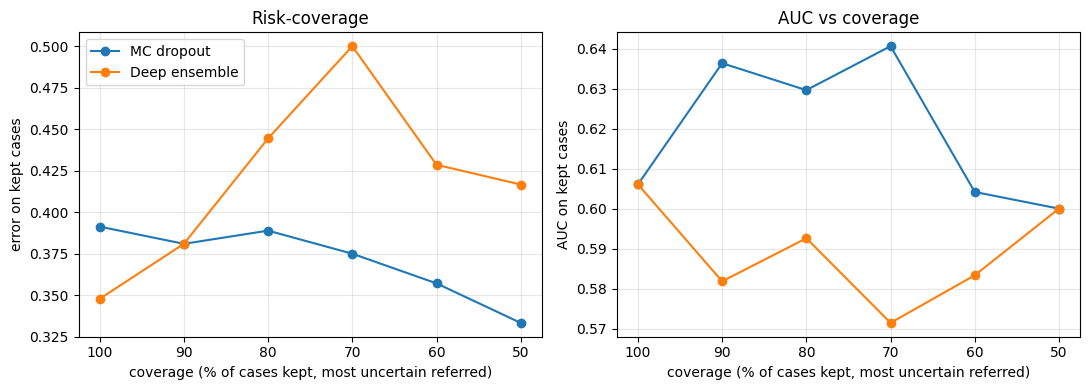

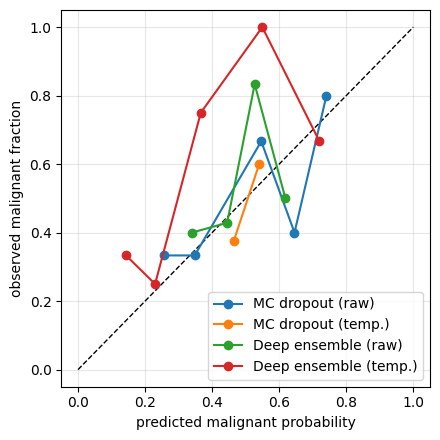

,method,calibration,AUC,ECE,Brier,error_detect_AUROC_entropy,error_detect_AUROC_mutual_info,AURC_entropy
0,MC dropout,raw,0.606,0.130,0.250,0.54,0.46,0.396
1,MC dropout,temperature-scaled (T=5.00),0.606,0.070,0.244,0.54,0.46,0.396
2,Deep ensemble,raw,0.606,0.131,0.246,0.35,0.60,0.402
3,Deep ensemble,temperature-scaled (T=0.45),0.606,0.301,0.264,0.35,0.60,0.402


In [4]:
methods = {'MC dropout': lambda P: T.mc_predict(clfs[0], P, cfg.mc_passes), 'Deep ensemble': lambda P: T.ensemble_predict(clfs, P)}
rows, curves, probs = [], {}, {}
for name, f in methods.items():
    uv, ut = f(P_va), f(P_te)
    temp = fit_temperature(uv['logit'], y_va); p_cal = apply_temperature(ut['logit'], temp)
    for tag, pp in [('raw', ut['p']), (f'temperature-scaled (T={temp:.2f})', p_cal)]:
        rows.append(dict(method=name, calibration=tag, AUC=auc_safe(y_te, pp), ECE=ece(y_te, pp), Brier=brier(y_te, pp),
                         error_detect_AUROC_entropy=error_detection_auroc(y_te, ut['p'], ut['ent']),
                         error_detect_AUROC_mutual_info=error_detection_auroc(y_te, ut['p'], ut['mi']),
                         AURC_entropy=aurc(y_te, ut['p'], ut['ent'])))
    curves[name] = risk_coverage(y_te, ut['p'], ut['ent']); probs[name + ' (raw)'] = ut['p']; probs[name + ' (temp.)'] = p_cal
unc = pd.DataFrame(rows).round(3); unc.to_csv(cfg.path('results', 'uncertainty_quality.csv'), index=False)
viz.plot_risk_coverage(curves, path=cfg.path('figures', '03_risk_coverage.png'))
viz.plot_reliability(y_te, probs, path=cfg.path('figures', '03_reliability.png'))
unc

**Reading it:** lower ECE/Brier = better calibrated; higher error-detection AUROC = uncertainty points at the cases the model gets wrong; lower AURC = better referral behaviour. The risk-coverage plot shows the error on the cases you keep after sending the most uncertain ones to a radiologist.

## 3. Uncertainty on damaged images (30% loss)

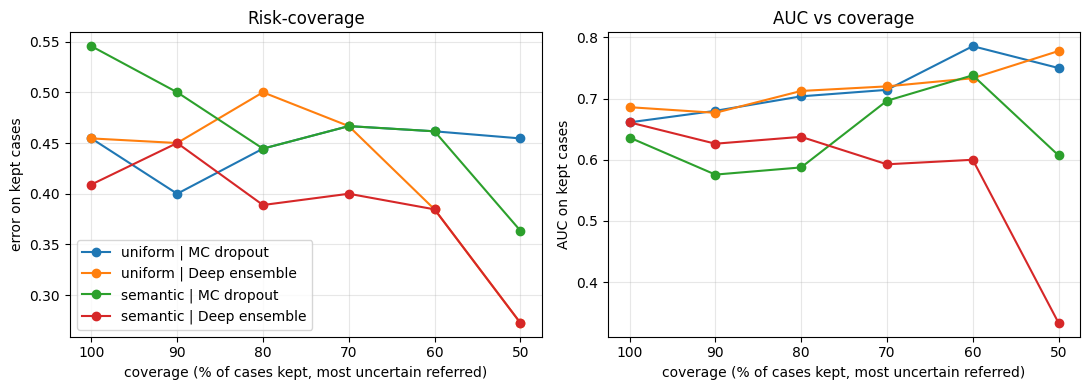

,scheme,method,AUC,ECE,error_detect_AUROC,AURC
0,uniform,MC dropout,0.661,0.189,0.608,0.321
1,uniform,Deep ensemble,0.686,0.156,0.667,0.273
2,semantic,MC dropout,0.636,0.262,0.725,0.366
3,semantic,Deep ensemble,0.661,0.081,0.556,0.348


In [5]:
X_te = images[te_df.img_idx.values]; M_te = masks[te_df.img_idx.values]; img01 = np.stack([T.to01(a) for a in X_te]); y_img = te_df.label.values
heat_te = T.predict_heatmaps(loc, X_te); imps_te = {s: build_importance(cfg, X_te, M_te, heat_te, s) for s in ['none', 'pred']}
rcv = {'MC dropout': Receiver(cfg, loc, [clfs[0]]), 'Deep ensemble': Receiver(cfg, loc, clfs)}
rows, curves = [], {}
for scheme, src in [('uniform', 'none'), ('semantic', 'pred')]:
    dmg, _ = damage_images(cfg, img01, imps_te[src], scheme, 0.3, seed=5)
    for name, r_ in rcv.items():
        r = diagnose_all(r_, dmg)
        rows.append(dict(scheme=scheme, method=name, AUC=auc_safe(y_img, r['p']), ECE=ece(y_img, r['p']),
                         error_detect_AUROC=error_detection_auroc(y_img, r['p'], r['ent']), AURC=aurc(y_img, r['p'], r['ent'])))
        curves[f'{scheme} | {name}'] = risk_coverage(y_img, r['p'], r['ent'])
dam = pd.DataFrame(rows).round(3); dam.to_csv(cfg.path('results', 'uncertainty_under_loss.csv'), index=False)
viz.plot_risk_coverage(curves, path=cfg.path('figures', '03_risk_coverage_under_loss.png')); dam

## 4. Adaptive loop: retransmit if uncertain, refer if still uncertain
The threshold is set on the **validation** images (flag the 30% most uncertain), never on the test set.

In [6]:
va_df = images_df[(images_df.split == 'val') & (~images_df.mixed)].reset_index(drop=True)
X_va = images[va_df.img_idx.values]; M_va = masks[va_df.img_idx.values]; img01_va = np.stack([T.to01(a) for a in X_va])
heat_va = T.predict_heatmaps(loc, X_va); imps_va = {s: build_importance(cfg, X_va, M_va, heat_va, s) for s in ['none', 'pred']}
ens = Receiver(cfg, loc, clfs)
rows = []
for scheme, src in [('uniform', 'none'), ('semantic', 'pred')]:
    for rate in (0.2, 0.3, 0.4):
        dv, _ = damage_images(cfg, img01_va, imps_va[src], scheme, rate, seed=11)
        thr = float(np.quantile(diagnose_all(ens, dv)['ent'], 0.70))
        res = adaptive_loop(cfg, ens, img01, imps_te[src], scheme, rate, thr, seed=3)
        rows.append(dict(scheme=scheme, rate=rate, entropy_threshold=round(thr, 3), **adaptive_summary(y_img, res)))
ad = pd.DataFrame(rows).round(3); ad.to_csv(cfg.path('results', 'adaptive_loop.csv'), index=False); ad

,scheme,rate,entropy_threshold,AUC_first_pass,AUC_after_retx,retransmitted_frac,extra_bandwidth,referral_rate,acc_first_pass,acc_non_referred,AUC_non_referred
0,uniform,0.2,0.692,0.479,0.512,0.182,0.007,0.091,0.364,0.350,0.540
1,uniform,0.3,0.692,0.537,0.554,0.227,0.016,0.091,0.500,0.500,0.535
2,uniform,0.4,0.690,0.488,0.512,0.591,0.045,0.227,0.455,0.529,0.614
3,semantic,0.2,0.691,0.777,0.818,0.318,0.009,0.227,0.727,0.824,0.829
4,semantic,0.3,0.691,0.711,0.636,0.455,0.015,0.227,0.545,0.647,0.667
5,semantic,0.4,0.692,0.760,0.669,0.273,0.011,0.091,0.682,0.600,0.616


**Reading it:** `AUC_after_retx` vs `AUC_first_pass` is the gain from retransmission; `extra_bandwidth` is its cost (fraction of all blocks re-sent); `referral_rate` is the share of cases still uncertain after retransmission and sent to a radiologist; `acc_non_referred` is accuracy on the cases the system keeps. A good result: accuracy up, referral rate modest, extra bandwidth small. Semantic transmission should need far fewer retransmissions than uniform because the lesion usually arrives intact.

Next: `04_active_learning.ipynb`.